# KQC QualityFactorTwoface — six capped spiral λ/4 resonators on one probe line (flip-chip lid) (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/quality_factor_twoface.py` (`QualityFactorTwoface`, default parameters, chip name
"CTest"), © IQM Finland Oy, GPL-3.0
(`other-libs/KQCircuits-main/.../kqcircuits/chips/quality_factor_twoface.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *QualityFactorTwoface*).

KQC's "preliminary class for flip-chip resonators": a probe line from the SMA8 launcher WN (PL-1-IN) to EN
(PL-1-OUT) that drops to y = 5000 µm under the top chip, with six T's at x = 3208 … 7292 µm. From each T's side
arm a finger or gap capacitor feeds a `SpiralResonatorPolygon` (a λ/4 wound inside a 2000 × 500 µm box, shorted at
its far end), alternately below and above the line. With the default `resonator_types = ["capped"] * 6` and
`resonator_faces = [0, 1]` every line is drawn on the bottom chip (face `1t1`); the top chip (face `2b1`) is a
metal lid ("capped") that has only its own KQC frame, and the probe line widens to the capped CPW
(a = 10, b = 10 µm) inside the top-chip box. KQC's face-change nodes on the probe line go to face 0 and back, so they
insert no flip-chip connector with these defaults.

**Kept exactly (same KQC cells, parameters and positions):** the SMA8 launcher assignment {8: PL-1-IN,
3: PL-1-OUT}; the probe line path with its two `WaveguideCoplanarTaper`s at the top-chip edge (10/6 ↔ 10/10 µm);
the six `WaveguideCoplanarSplitter`s (lengths 15/15/65 µm, side arm down for even, up for odd resonators) at KQC's
positions; the six `FingerCapacitorSquare`s from KQC's `cap_params` (interdigital 4 × 23.1, 4 × 9.9, 2 × 14.1 µm; gap
10, 21, 28 µm; 10/10 µm on the line side, the resonator's a/b on the other), snapped port `a` to the T's side arm as
KQC aligns them; the resonator lengths 5434 / 5429 / 5374 / 5412 / 5493 / 5589 µm with KQC's widths
(a/b = 10/6, 10/6, 10/6, 20/12, 10/6, 5/3 µm) and KQC's spiral path. Results 6 XORs the chip with a stand-alone KQC build.

**Substituted:** each `SpiralResonatorPolygon` is a Designer route (C*i*.b → shorted free end) whose waypoints are
the centre line KQC's `SpiralResonatorPolygon` computes for the same parameters (built in a scratch layout in the
layout cell). The reason: the spiral's `input_path` / `poly_path` are `DPath` shapes, which `design.json` cannot
carry yet (open request). The route draws the same `WaveguideCoplanar`, and
the LOM sees a λ/4 route to a shorted end.

**Not modelled:** the lid. The LOM is face-agnostic, so the resonators are bare planar λ/4 lines; the top chip's ground shifts their frequencies (it changes the lines' ε_eff and impedance), and the FEM export has one face too (the PDK `face_stack` lists the bottom chip only), so the lid is in neither model yet (request in the log).

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | SMA8, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in); same assignment |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (28 µm off in y, inside the 50 µm tolerance: no shift) |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its two SMA8 launchers, the launchers and the pad rule, the probe line's six T's and coupling capacitors, the six spiral λ/4 resonators (the test structures), the probe line through the T's, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `quality_factor_twoface.v1.ipynb`; both save the same `quality_factor_twoface.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/quality_factor_twoface/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/quality_factor_twoface")  # step-by-step snapshots (build/ is not kept in the repo)
FACES = ["1t1", "2b1"]                                        # KQC resonator_face_ids (bottom chip, lid)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way it is laid out by hand: the die and its launchers, the line's parts, what hangs on the
line, the line itself, and then the whole chip. A resonator test chip has no qubits and nothing couples its resonators
to each other (each couples to the line only through its own capacitor), so the resonators take the qubits' place and
there is no coupling segment. The capacitors sit on the T's side arms and the spirals start at the capacitors (`snap`,
`port_info`), so T → C → R keeps the v1's order; the probe line only joins T ports and launcher ports, so it can come
after the resonators (the v1 drew it before them: `save_design` writes the v1's key order back). KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 holder's two launchers (WN PL-1-IN, EN PL-1-OUT) |
| 2 | the launchers and the pad rule (they come with the die): nothing added, the check and a zoom |
| 3 | the readout line's parts: six probe-line T's at y = 5000 µm and the six coupling capacitors on their side arms |
| 4 | the test structures (in place of qubits): six spiral λ/4 resonators, each from its capacitor to a shorted end |
| 5 | the routing: the probe line, launcher → taper to the capped CPW → T0 … T5 → back out |
| 6 | the whole chip: one eigenmode sim group per resonator, the centring check, the save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID) and KQC's SMA8 launcher assignment for this chip (only the assigned pads are drawn). `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

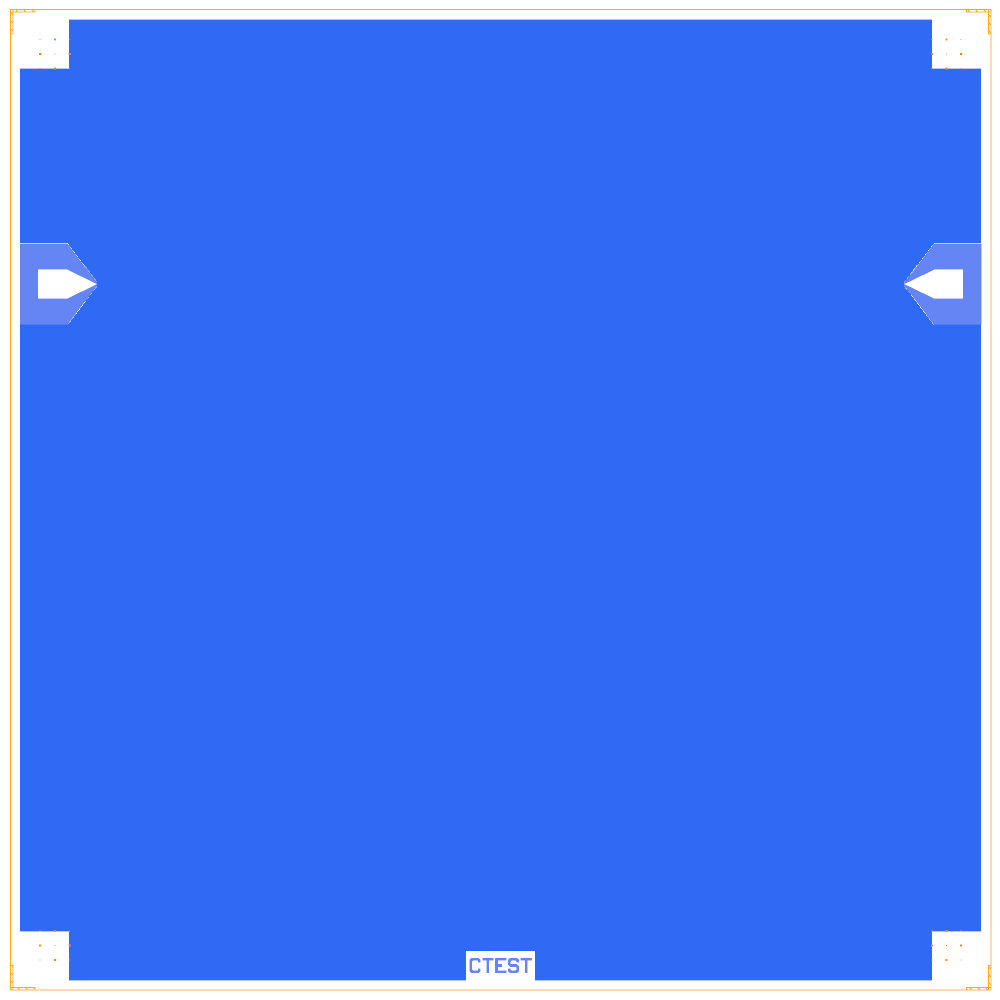

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/quality_factor_twoface/1_die.png')

In [5]:
d = Designer("quality_factor_twoface", box=(0, 0, 10000, 10000),
             launchers={"type": "SMA8", "assign": {8: "PL-1-IN", 3: "PL-1-OUT"}},
             chip={"name_chip": "CTest", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For SMA8 (RF launcher:
300 µm taper + 300 µm pad + 180 µm frame gap) the Designer sets `launcher_indent` = 100 + 300 + 300 + 180 =
**880 µm** (KQC: 800 µm). Every line below starts at a launcher port or at a waypoint taken from one, so the 80 µm
shift needs no other change.

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on PL-1-IN.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.PL-1-OUT | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.PL-1-IN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

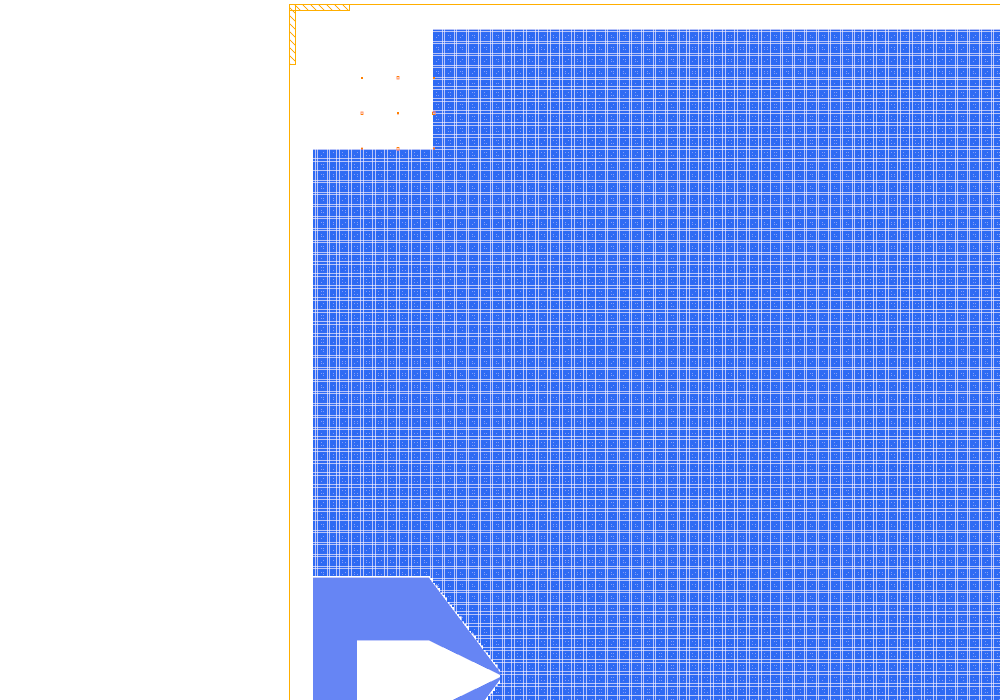

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.PL-1-IN")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Readout: the probe line's T's and the coupling capacitors

The probe line runs at y = 5000 µm under the top chip on the capped CPW (a = b = 10 µm) through six T's
(`WaveguideCoplanarSplitter`, arms 15 / 15 / 65 µm, the side arm down for the even resonators and up for the odd ones)
at x = 3208 … 7292 µm. On each side arm a `FingerCapacitorSquare` from KQC's `cap_params`, snapped by its port `a`,
couples one resonator to the line: interdigital 4 × 23.1, 4 × 9.9 and 2 × 14.1 µm fingers for R0–R2, gaps of 10, 21
and 28 µm for R3–R5. The capacitors set each resonator's κ into the line (Q_ext, what the chip measures). The first
picture is the chip so far, the second zooms on T0 with C0 below it.

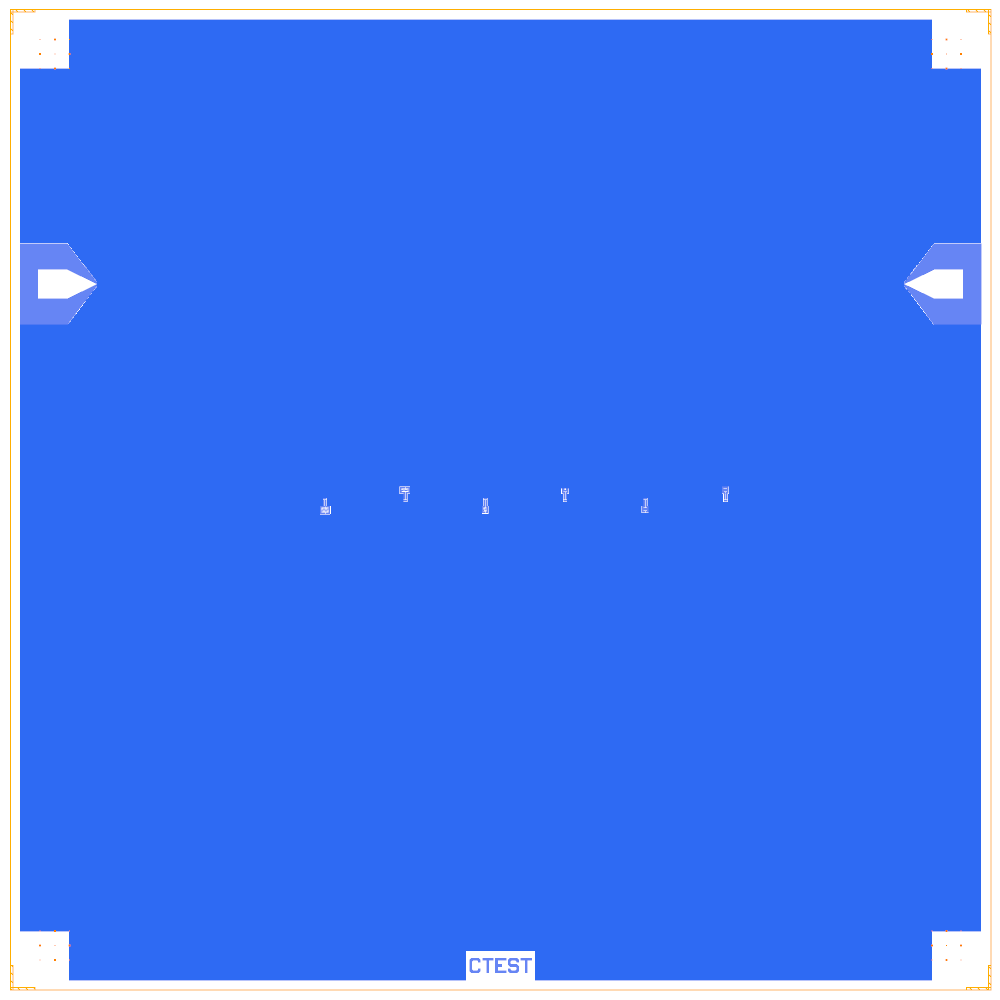

**On the chip so far:** 0 pads · 0 qubits · 12 other components · 0 routes · 0 declared couplings. **This step added** 12 component(s) `T0`, `T1`, `T2`, `T3`, `T4`, `T5`, `C0`, `C1` … (+4).

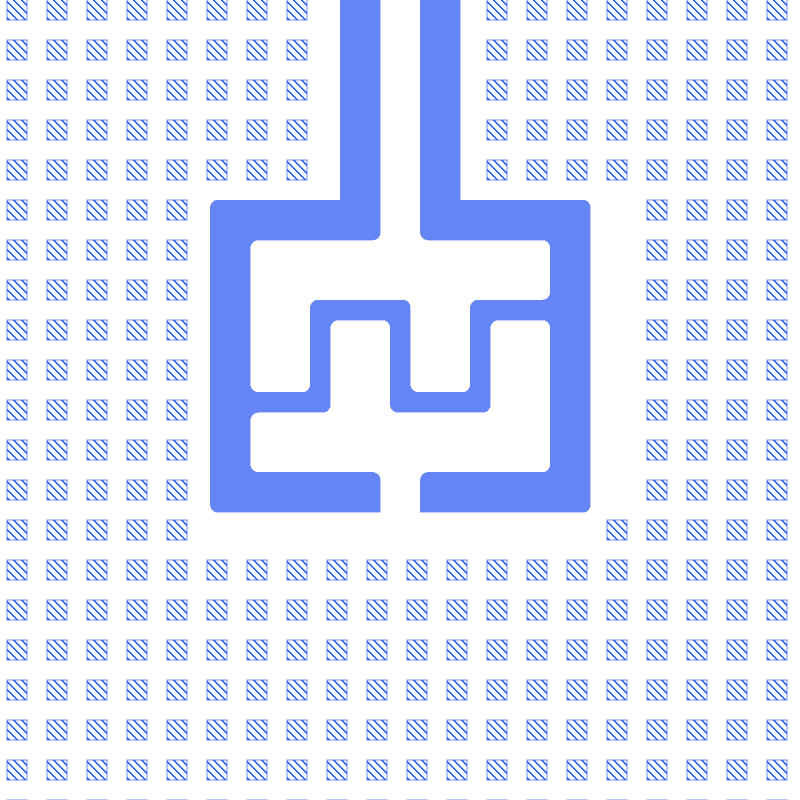

In [7]:
# KQC defaults (QualityFactor lists, QualityFactorTwoface widths and geometry)
res_lengths = [5434, 5429, 5374, 5412, 5493, 5589]
n_fingers, l_fingers = [4, 4, 2, 4, 4, 4], [23.1, 9.9, 14.1, 10, 21, 28]
coupler = ["interdigital", "interdigital", "interdigital", "gap", "gap", "gap"]
res_a, res_b = [10, 10, 10, 20, 10, 5], [6, 6, 6, 12, 6, 3]
a, b, a_c, b_c, r = 10, 6, 10, 10, 100               # chip CPW, capped CPW (a_capped, b_capped), turn radius
top = (1500, 1500, 8500, 8500)                         # top-chip (face 1) box
spiral_h, spiral_w, cap_res, x_indent, wg_indent = 2000, 500, 200, 800, 500
left_x, right_x = top[0] + wg_indent, top[2] - wg_indent
left_c, right_c, mid_y = top[0] + x_indent, top[2] - x_indent, (top[1] + top[3]) / 2
spacing = (right_c - left_c - spiral_w) / 6
xs = [left_c + spiral_w + (i + 0.5) * spacing for i in range(6)]
tee = a_c / 2 + b_c                                    # KQC tee_length; the side arm is 5·a_capped longer


def cap_params(fingers, length, kind):               # KQC util.coupler_lib.cap_params
    p = dict(finger_number=fingers, finger_length=length, finger_gap_end=5, finger_gap=5, finger_width=15,
             ground_padding=10)
    if kind == "gap":
        p |= dict(finger_length=0, finger_gap_end=length, finger_gap=0, finger_width=10)
    return p


with d.batch():
    # probe-line T's (KQC splitter nodes: angles [0, 180, side], entered from the left, so rotated 180°)
    for i, x in enumerate(xs):
        d.add(f"T{i}", "WaveguideCoplanarSplitter", at=(x, mid_y), rot=180, angles=[0, 180, 90 if i % 2 == 0 else 270],
              lengths=[tee, tee, tee + 5 * a_c], a=a_c, b=b_c)
    # input capacitors: port a on the T's side arm (KQC align="port_a"), resonator a/b on port b
    for i in range(6):
        d.add(f"C{i}", "FingerCapacitorSquare", snap="a", to=f"T{i}.c", a=a_c, b=b_c, a2=res_a[i], b2=res_b[i],
              face_ids=FACES, **cap_params(n_fingers[i], l_fingers[i], coupler[i]))
layout_step(d, STEPS / "s3_couplers.png", **CHIP)
x, y = port_xy(d, "T0.c")
snap(d, STEPS / "s3_c0.png", box=(x - 100, y - 150, x + 100, y + 50), size=(800, 800), width=320);

## Design 4 · The test structures: six spiral λ/4 resonators

Each resonator is a λ/4 wound inside a 2000 × 500 µm box, from its capacitor's port `b` to a shorted end, alternately
below (even) and above (odd) the line: lengths 5434 / 5429 / 5374 / 5412 / 5493 / 5589 µm with KQC's widths (a/b =
10/6, 10/6, 10/6, 20/12, 10/6, 5/3 µm). It is a Designer route on the centre line that KQC's `SpiralResonatorPolygon`
computes for the same parameters (`spiral_path` builds the cell in a scratch layout and reads its path), so the route
draws the same `WaveguideCoplanar` and the LOM sees a λ/4 to a shorted end. The spiral starts at the capacitor's port
(`port_info`), so the resonators come after the capacitors. The first picture is the chip so far, the second zooms on
R1 (Fab 2 shows R0).

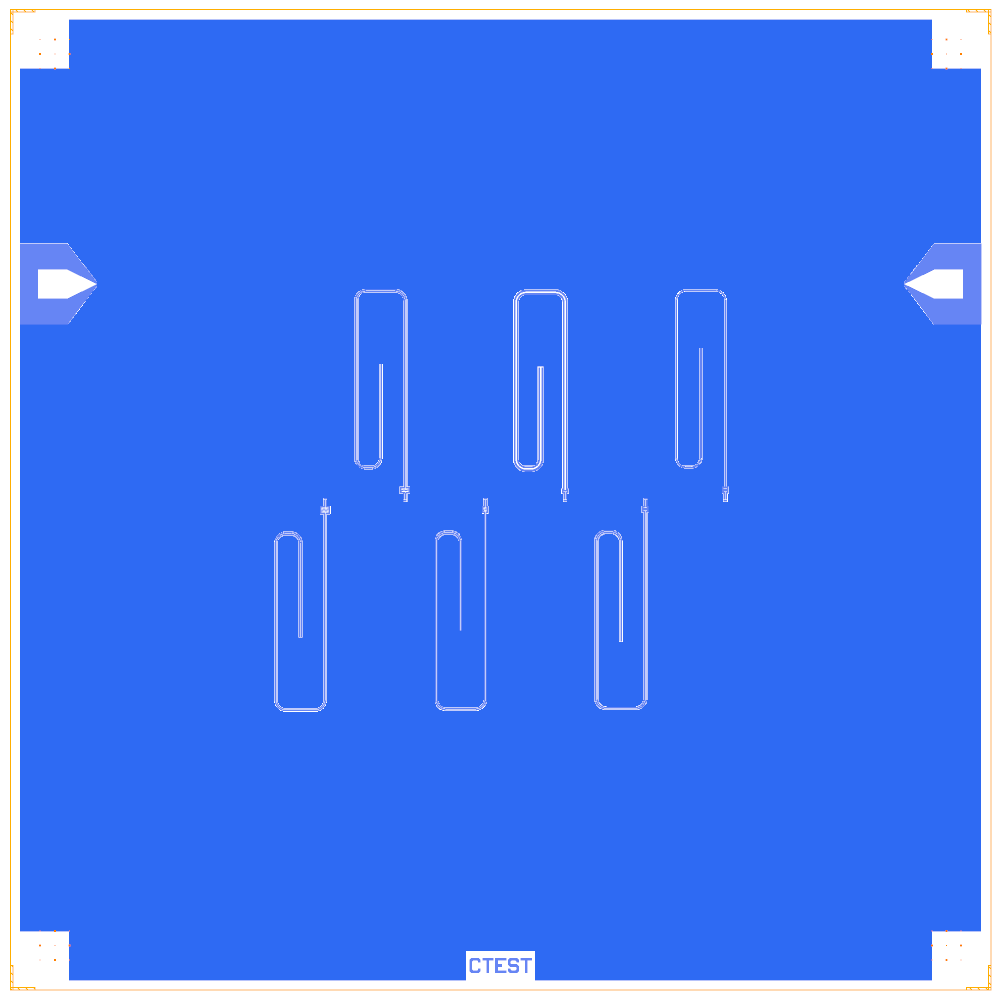

**On the chip so far:** 0 pads · 0 qubits · 12 other components · 6 routes · 0 declared couplings. **This step added** 6 route(s) `R0`, `R1`, `R2`, `R3`, `R4`, `R5`.

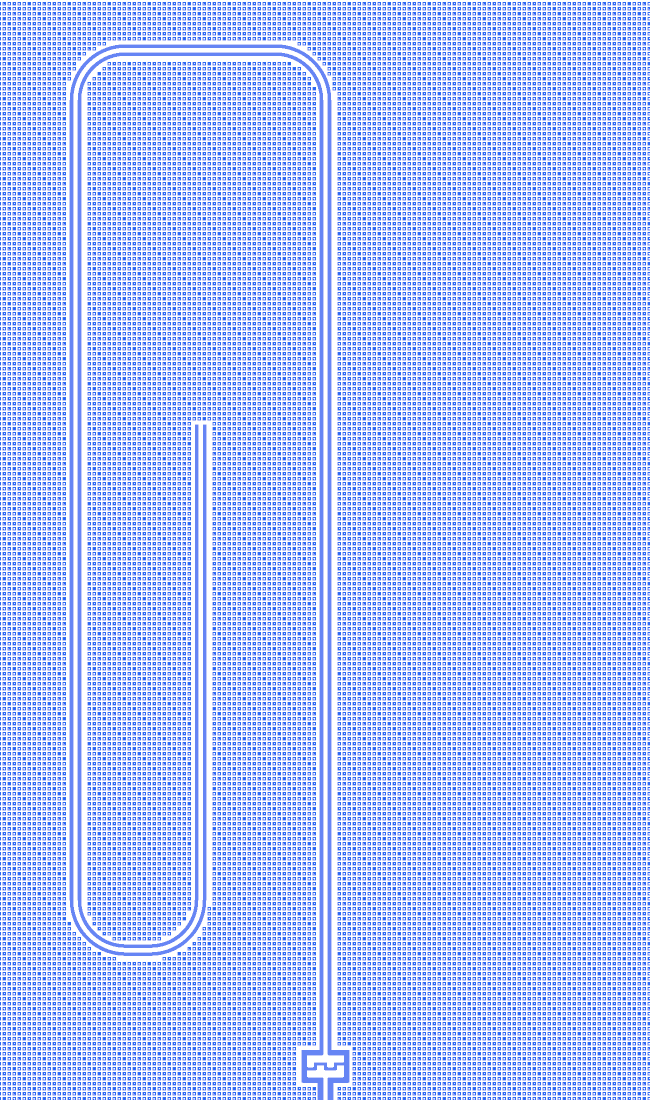

In [8]:
def spiral_path(i):
    """Centre line of KQC's SpiralResonatorPolygon for resonator i (local frame, port a at the origin)."""
    from kqcircuits.elements.spiral_resonator_polygon import SpiralResonatorPolygon
    ly = pya.Layout()
    box = [pya.DPoint(cap_res, 0), pya.DPoint(spiral_h, 0), pya.DPoint(spiral_h, -spiral_w), pya.DPoint(cap_res, -spiral_w)]
    cell = SpiralResonatorPolygon.create(ly, input_path=pya.DPath([pya.DPoint(0, 0)], 10), poly_path=pya.DPath(box, 10),
                                         length=res_lengths[i], a=res_a[i], b=res_b[i], r=r, margin=5,
                                         bridge_spacing=0, face_ids=FACES)
    wg = ly.cell(next(cell.each_inst()).cell_index)    # its one WaveguideCoplanar
    path = wg.pcell_parameters_by_name()["path"]
    return [(p.x, p.y) for p in (path.each_point() if hasattr(path, "each_point") else path)]


with d.batch():
    # spiral λ/4 resonators: KQC places the spiral at C_i.b with DCplxTrans(1, side-arm angle, mirror = odd i)
    for i in range(6):
        x, y, ang = port_info(d, f"C{i}.b")
        tr = pya.DCplxTrans(1, ang, i % 2 == 1, x, y)
        pts = [tr * pya.DPoint(*p) for p in spiral_path(i)]
        d.route(f"R{i}", f"C{i}.b", Designer.free_end((pts[-1].x, pts[-1].y), term=0), a=res_a[i], b=res_b[i],
                nodes=[(p.x, p.y) for p in pts[1:-1]])
layout_step(d, STEPS / "s4_resonators.png", **CHIP)
x, y = port_xy(d, "C1.b")
snap(d, STEPS / "s4_r1.png", box=(x - 650, y - 100, x + 650, y + 2100), size=(650, 1100), width=300);

## Design 5 · Routing: the probe line

From PL-1-IN the line comes in on the chip CPW (a = 10, b = 6 µm), widens to the capped CPW (a = b = 10 µm) at a
waypoint on the top-chip edge (KQC's `WaveguideCoplanarTaper` there), drops to y = 5000 µm, runs through T0 … T5
(five short routes between them) and goes back up and out to PL-1-OUT the same way. Every end is a T port or a
launcher port. The picture is the whole chip (the v1's).

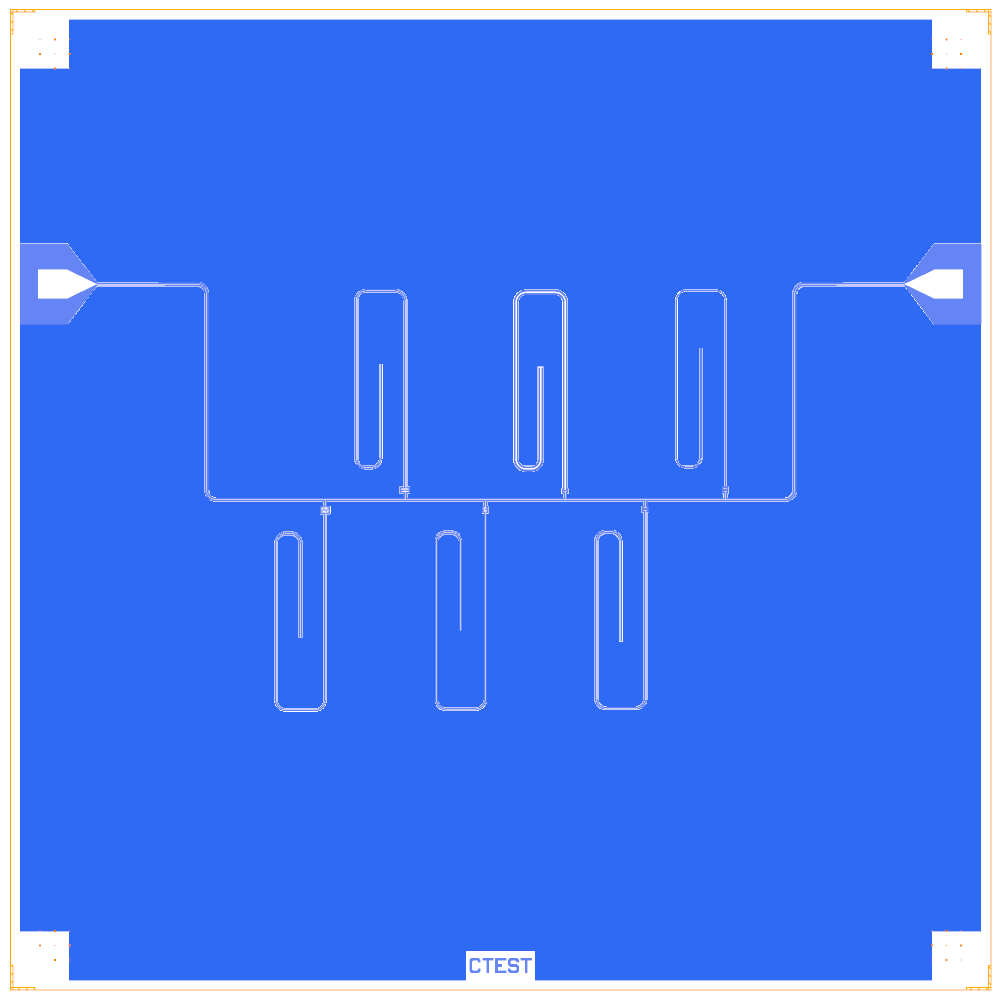

**On the chip so far:** 0 pads · 0 qubits · 12 other components · 13 routes · 0 declared couplings. **This step added** 7 route(s) `PL_in`, `PL_01`, `PL_12`, `PL_23`, `PL_34`, `PL_45`, `PL_out`.

{'R0': 5434.0, 'R1': 5429.0, 'R2': 5374.0, 'R3': 5412.0, 'R4': 5493.0, 'R5': 5589.0, 'PL_in': 4427.49, 'PL_01': 786.67, 'PL_12': 786.67, 'PL_23': 786.67, 'PL_34': 786.67, 'PL_45': 786.67, 'PL_out': 3927.49}


In [9]:
with d.batch():
    # probe line: launcher → taper to the capped CPW at the top-chip edge → down to y = 5000 → T0 … T5 → back up
    d.route("PL_in", "chip.PL-1-IN", "T0.a", a=a, b=b,
            nodes=[d.waypoint((top[0], 7200), a=a_c, b=b_c), (left_x, 7200), (left_x, mid_y)])
    for i in range(5):
        d.route(f"PL_{i}{i + 1}", f"T{i}.b", f"T{i + 1}.a", a=a_c, b=b_c)
    d.route("PL_out", "T5.b", "chip.PL-1-OUT", a=a_c, b=b_c,
            nodes=[(right_x, mid_y), (right_x, 7200), d.waypoint((top[2] - 100, 7200), a=a, b=b)])
layout_step(d, STEPS / "4_routes.png", **CHIP)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

## Design 6 · The whole chip: sim groups, centring, save

One eigenmode sim group per resonator (its T, capacitor and spiral, 200 µm margin); the FEM export draws the bottom chip only, so the lid is not in the box (Simulate 1). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved with `save_design`, which compares it with the file it replaces (the
previous run's): the probe line came after the resonators here, so `save_design` writes the previous file's key order
back, and it should say *same design*.

In [10]:
for i in range(6):
    d.sim_group(f"R{i}", [f"T{i}", f"C{i}", f"R{i}"], margin_um=200, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "quality_factor_twoface.json")
display(Markdown(same))
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/quality_factor_twoface.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer quality_factor_twoface: 12 instances, 13 routes, live=False> → examples\designs\kqc\test_chips\quality_factor_twoface.json


# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean: no errors, no warnings and no PDK design warning. `pdk_report` gives KQC's grid ("the original design's own"), the content 28 µm off in y and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [ ]:
lb = d.lom()
show_netlist(lb)

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Six linear modes (QuCat): frequency and external κ into the two 50 Ω launchers; no junctions, so no anharmonicity.
These are planar estimates: the LOM is face-agnostic, so the lid is not in them (its ground changes the lines' ε_eff and impedance; the FEM export has one face too, Simulate 1). `kqc/qualityfactor` has the same six lengths and couplers as straight λ/4s on an uncapped line.

In [ ]:
res = simulate_lom(lb, d.design, max_modes=2)
display(Markdown(modes_md(res)))
Q = {m.label: m.f_GHz * 1e3 / m.kappa_MHz for m in res.modes if m.kappa_MHz}
display(Markdown("| mode | Q_ext (LOM) |\n|---|---|\n" + "\n".join(f"| {k} | {v:.3g} |" for k, v in sorted(Q.items()))))

**From the v1 run:** six modes from 5.578 (R5) to 5.795 GHz (R2), each on its own line, with Q_ext from 4.0 × 10³ (R0) to 1.25 × 10⁵ (R4): the interdigital couplers (R0–R2) couple more strongly than the gap couplers (R3–R5). The lid is not in these numbers.

## LOM 2 · The LOM in a plot

The same result as a picture: (a) the six resonator modes (QuCat; squares are resonators), (b) the dispersive-shift
panel stays empty: no qubits, no χ.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="quality_factor_twoface: LOM")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. The coupling capacitor sets Q_ext. Lengthen R0's interdigital fingers from 23.1 to 40 µm: the coupling capacitance
grows, so R0's κ rises (Q_ext falls) and its f_r drops slightly; the other five keep their frequencies. The change is made on
a copy (`design_copy`), so `quality_factor_twoface.json` keeps KQC's 23.1 µm.

In [ ]:
d2 = design_copy(DESIGN)
d2["C0"].set(finger_length=40)
res2 = simulate_lom(d2.lom(), d2.design, max_modes=2)
m0, m1 = {m.label: m for m in res.modes}, {m.label: m for m in res2.modes}
display(Markdown("**C0 fingers: 23.1 → 40 µm**\n\n| mode | f before (GHz) | f after (GHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |"
                     for k in m0 if k in m1)))

**Result (from the v1 run).** R0 moves from 5.6522 to 5.6325 GHz (−20 MHz) and its κ from 1.42 to 2.65 MHz (Q_ext 4.0 × 10³ → 2.1 × 10³). R4, the nearest mode (30 MHz up), also changes its κ (0.046 → 0.073 MHz) through the shared probe line; the other four do not move.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/test_chips/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

On this chip: one eigenmode job per resonator (its T, capacitor and spiral): the probe line leaving the box ends in 50 Ω, so the solve gives f_r and Q_ext (of the bottom chip, see below).

**One face.** The export draws the bottom chip (`1t1`) only: the PDK's `face_stack` has one face
(`sim_tools/builder.py`), so the lid (the top chip, `2b1`) is in neither the LOM nor the FEM box, and its effect needs
a two-face export (request in the log). What the FEM adds here is the real geometry: the spiral's turns, the
capacitors and the T's.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/test_chips/fem/: solved results are kept here
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")   # one eigenmode job per resonator (the groups' own analysis)
display(Markdown(jobs_md(jobs_eig)))

## Simulate 2 · Component simulation: none here

The component step of the plugin is a Q3D C-matrix per group. A shorted λ/4 joins the ground plane at its far end, so
in a C-matrix it is part of ground: the job would hold the probe line and the capacitor's line side only. The
resonators' frequencies and κ come from the eigenmode (Simulate 3) and the driven run (Simulate 4); the sim groups ask
for the eigenmode only.

## Simulate 3 · Eigenmode simulation

Each resonator's box in HFSS eigenmode: the two probe-line routes leaving it end in 50 Ω, so the resonator mode's Q
gives its κ into the line (Q_ext, what this chip measures, plus the box's other losses).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the probe line through R1's box (R1 is the feedback's resonator, Results 4): the
resonator is a notch, which is how this chip is measured. The library cannot hand the solved eigenmode **mesh**
itself to a driven setup (no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim
group and box, the eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's mode nearest R1 (the
LOM's f before the eigenmode is solved) and a fast sweep from 0.4 GHz below to 0.2 GHz above it.

In [ ]:
lom_r = {m.label: m for m in res.modes}          # the LOM's resonator modes (LOM 1)

f_drv = lom_r["R1"].f_GHz   # the LOM's R1 frequency
jobs_drv = driven_from_eigenmode(DESIGN, "R1", jobs_eig["R1"][0], keep_eig["R1"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["R1"]:
    display(Markdown(driven_md(keep_drv["R1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q (no junction: every p_J is 0), with the LOM's six resonator frequencies as dashed lines. The tables below list the
modes.

In [ ]:
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom={k: m.f_GHz for k, m in lom_r.items()})
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

Each LOM resonator against the eigenmode of its own box: `match_modes` picks the solved mode (Q > 100) nearest the
LOM's f. κ = f/Q of the 50 Ω-terminated box and Q_ext = f/κ = Q; the driven run adds R1's notch fit.

In [ ]:
fem_r = {g: match_modes(keep_eig.get(g), {g: lom_r[g].f_GHz}).get(g) for g in keep_eig}
rows = []
for g, e in fem_r.items():
    m = lom_r[g]
    rows.append(f"| `{g}` | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.f_GHz * 1e3 / m.kappa_MHz:,.0f} | "
                + (f"{e['f_GHz']:.4f} | {1e3 * e['f_GHz'] / e['Q']:.3g} | {e['Q']:,.0f} |" if e else "– | – | – |"))
if any(fem_r.values()):
    display(Markdown("| resonator | LOM f (GHz) | LOM κ (MHz) | LOM Q_ext | FEM f (GHz) | FEM κ (MHz) | FEM Q |\n"
                     "|---|---|---|---|---|---|---|\n" + "\n".join(rows)))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would put each resonator's LOM f, κ and Q_ext next "
          "to its eigenmode f, κ and Q.")
if keep_drv["R1"]:
    print("R1, driven notch:", driven_values(keep_drv["R1"], "R1", f_drv))

## Results 3 · FEM against the LOM

The LOM's f and κ of each resonator (LOM 1) next to the eigenmode's, with the difference in %. The LOM's λ/4 is the
drawn length on a CPW formula; the FEM adds the spiral's turns and the coupler's real geometry, so expect an offset
of a few per cent (neither has the lid).

In [ ]:
rows = []
for g, e in fem_r.items():
    if e:
        m = lom_r[g]
        rows += [(f"{g}.f_GHz", m.f_GHz, e["f_GHz"], "eigenmode"),
                 (f"{g}.kappa_MHz", m.kappa_MHz, 1e3 * e["f_GHz"] / e["Q"], "eigenmode, f/Q")]
if keep_drv["R1"]:
    rows += [(k, lom_r["R1"].f_GHz if k.endswith("f_GHz") else lom_r["R1"].kappa_MHz, x, "driven S21 notch")
             for k, x in driven_values(keep_drv["R1"], "R1", f_drv).items()]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts each resonator's LOM f and κ next to the "
          "eigenmode's (and R1's driven notch), with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `QualityFactorTwoface` states no frequencies, so this notebook sets one as an exercise: **R1 at 5.730 GHz**. On
the LOM R1 and R4 sit only 6.4 MHz apart (from the v1 run: 5.6882 and 5.6818 GHz, with κ ≈ 0.74 and 0.05 MHz), so
their dips would be hard to tell apart in a measurement; at 5.730 GHz R1 sits ≈ 48 MHz above R4 and ≈ 43 MHz below R3
(5.7734 GHz in the v1 run). There is no qubit, so `loop.feedback` (which tunes qubit–readout pairs) does not apply;
the feedback is the first-order rule of a λ/4, f ∝ 1/ℓ, so R1's new length is ℓ · f / f_target (≈ 5429 → 5389 µm
here). The knob is the spiral's length: `spiral_revision` redraws R1 on KQC's spiral centre line for the new length
(the Design 4 call with that length, on the same capacitor port with the same widths). When an eigenmode of R1 is
kept, the LOM is first scaled by FEM / LOM (`SCALE`), so the step aims at the FEM value (still without the lid). The
target goes on a copy (`target_copy` → `build/quality_factor_twoface_target.json`); the revisions are copies of it,
and the design file keeps KQC's lengths. The revision is checked on the LOM here, not built (a build draws KQC's grid,
≈ 0.9 M holes).

In [ ]:
def spiral_revision(path_t, i, length, it):
    """Revision it of the design at path_t: resonator R<i> redrawn on KQC's spiral centre line for `length` (the
    Design 4 call with that length: same capacitor port, widths and shorted end), saved to build/."""
    d2 = design_copy(path_t, f"_rev{it}")
    keep_len = res_lengths[i]
    res_lengths[i] = length                      # spiral_path (Design 4) reads res_lengths[i]
    try:
        x, y, ang = port_info(d2, f"C{i}.b")
        tr = pya.DCplxTrans(1, ang, i % 2 == 1, x, y)
        pts = [tr * pya.DPoint(*p) for p in spiral_path(i)]
    finally:
        res_lengths[i] = keep_len
    d2.route(f"R{i}", f"C{i}.b", Designer.free_end((pts[-1].x, pts[-1].y), term=0), a=res_a[i], b=res_b[i],
             nodes=[(p.x, p.y) for p in pts[1:-1]])
    return d2, d2.save(Path("build") / f"quality_factor_twoface_rev{it}.json")


I_T, F_T, F_TOL = 1, 5.730, 0.001                # the exercise target: R1 at 5.730 GHz ± 1 MHz
R_T = f"R{I_T}"
DESIGN_T = target_copy(DESIGN, {R_T: {"f_GHz": F_T}})
f_lom = lom_r[R_T].f_GHz
f_fem = (fem_r.get(R_T) or {}).get("f_GHz")
SCALE = f_fem / f_lom if f_fem else 1.0          # FEM / LOM at the drawn length (1: the LOM alone)
L0 = float(res_lengths[I_T])
L1 = rule_step(L0, SCALE * f_lom, F_T, -1.0)
display(Markdown(f"**{R_T}:** now {SCALE * f_lom:.4f} GHz ({'FEM' if f_fem else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"spiral length {L0:.1f} → **{L1:.1f} µm** (f ∝ 1/ℓ)"))
d1, rev1 = spiral_revision(DESIGN_T, I_T, L1, 1)
r1 = {m.label: m for m in simulate_lom(d1.lom(), d1.design, max_modes=2).modes}
print(f"revision 1: {rev1} · {R_T} on the LOM {r1[R_T].f_GHz:.4f} GHz, × SCALE {SCALE * r1[R_T].f_GHz:.4f} GHz "
      f"(target {F_T} GHz)")

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the length, its LOM runs (× `SCALE`), and the next step uses the
exponent of the last two points (a secant), until R1 is within 1 MHz or `MAX_ITER` steps are made; the length stays
between 0.9 × its own and the chip's longest spiral (5589 µm, which KQC fits in the same box). With `RUN_FEM = True`
each revision's R1 eigenmode is exported to `build/jobs/rev<k>/` and solved (minutes each), and the loop closes on the
FEM's R1.

In [ ]:
def f_r1_of(k, it):
    """Revision it: R1 redrawn k µm long; its frequency on the LOM (× SCALE), or from its own eigenmode with RUN_FEM."""
    d2, path = spiral_revision(DESIGN_T, I_T, k, it)
    r = {m.label: m for m in simulate_lom(d2.lom(), d2.design, max_modes=2).modes}
    if RUN_FEM:
        job = export_sims(path, [R_T], analysis="eigenmode_epr", root=f"build/jobs/rev{it}")
        keep = fem_stage(job, RUN_FEM, KEEP / f"rev{it}", force=RESOLVE, aedt=AEDT_MODE)[R_T]
        e = match_modes(keep, {R_T: r[R_T].f_GHz}).get(R_T)
        if e:
            return e["f_GHz"], path
    return SCALE * r[R_T].f_GHz, path


history = rule_iterate(f_r1_of, f"{R_T}.f_GHz", f"{R_T}.length", L0, F_T, F_TOL, -1.0, max_iter=MAX_ITER,
                       start=(SCALE * f_lom, DESIGN_T), fem=bool(RUN_FEM), bounds=(0.9 * L0, max(res_lengths)))
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", history[-1]["design"], "· on target:", history[-1]["on_target"])

## Results 6 · The layout against the source: XOR with KQC

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers with their lines' first legs (80 µm deeper here). A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.quality_factor_twoface import QualityFactorTwoface as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

**From the v1 run:** the XOR (1.75 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer alone 1 × 10⁸ µm²), the ground grid and its avoidance, KQC's frames on both faces (on the lid the frame is all KQC draws: base etch 4.6 × 10⁶ µm²) and the launcher shift; the waveguide path differs by only 1.6 × 10³ µm² (the probe line's first legs).

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `quality_factor_twoface.json` (saved in Design 6) is the whole design: `qcc build
examples/designs/kqc/test_chips/quality_factor_twoface.json` rebuilds `build/quality_factor_twoface.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In the v1 run: 1/0 919 066 polygons, 3/0 910 306; cheese source `build`, 919 060 holes (the bottom chip). The lid draws no shapes of its own here (only KQC's frame did), so there is no 800/0. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/quality_factor_twoface.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and R0's coupler on its T in the **fab view** (the mask from Fab 1: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "quality_factor_twoface.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "quality_factor_twoface_r0.png", box=(2600, 2750, 3400, 5100), size=(800, 1600), width=320)
x, y = port_xy(d, "T3.c")
show_snapshot(d, OUT / "quality_factor_twoface_c3.png", box=(x - 90, y - 90, x + 90, y + 90), width=360)
show_snapshot(d, OUT / "quality_factor_twoface_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "quality_factor_twoface_fab.oas", OUT / "quality_factor_twoface_fab.png", box=(3050, 4850, 3450, 5250), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the launchers 80 µm further in (outer etch 100 µm, `frame.pad_edge`); sapphire; KQC's grid on the bottom chip; no frame on the lid |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | 6 eigenmode jobs and R1's driven job exported (`build/jobs/quality_factor_twoface_R*`), not solved here; one face (the lid is not exported) |
| layout | built in six segments (die and launchers, the launcher check, the T's and capacitors, the six spiral resonators, the probe line, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (R1 5.730 GHz, away from R4): the λ/4 rule f ∝ 1/ℓ on R1's spiral length, iterated with a secant (LOM × FEM/LOM scale; eigenmode per revision with `RUN_FEM`) |
| open | the FEM jobs (eigenmode, driven) are exported, not solved (`RUN_FEM = False`); the lid is in neither the LOM nor the one-face FEM export |